# Train and evaluate

Trains an XGBoost model to distinguish bankrupt from active Finnish companies, evaluates it on companies it has never seen, and explains its predictions with SHAP.

- **Input:** `data/model_data.csv` from `01_Build_dataset`, one row per company (its latest year of accounts).
- **Output:** aggregate result tables in `results/`, read by the Streamlit app, plus a small demo model for the app's risk calculator. No company-level data is written to `results/`.

## 1. Setup

In [1]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap

from sklearn.model_selection import train_test_split, StratifiedKFold, learning_curve
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve, confusion_matrix,
    precision_score, recall_score, f1_score,
)

# ── Paths ─────────────────────────────────────────────────────
DATA_PATH   = os.path.join("data", "model_data.csv")
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ── Fixed settings ────────────────────────────────────────────
RANDOM_STATE = 42
TARGET       = "Bankrupt"
INDUSTRY     = "NACE Section"

# Population counts from the Moody's (Orbis) search results
# screen — not derivable from the exported files, because only a
# random sample of active companies could be exported.
UNIVERSE_TOTAL    = 64_052
UNIVERSE_BANKRUPT =  1_136
UNIVERSE_ACTIVE   = UNIVERSE_TOTAL - UNIVERSE_BANKRUPT

# Model inputs, listed explicitly so a new column in the data
# file never silently becomes a feature. Not used on purpose:
#   company_id, company name — identifiers
#   Year, n_years_reported   — reveal when a company's records
#                              end, not its financial health
NUMERIC_FEATURES = [
    "Company Age",
    "Total assets",
    "Current assets",
    "Current liabilities",
    "Shareholders funds",
    "P/L before tax",
    "FE_total_liabilities",
    "FE_non_current_assets",
    "FE_debt_ratio",
    "FE_current_ratio",
    "FE_roa",
    "FE_negative_equity",
    "FE_negative_pl",
    "FE_assets_yoy_growth",
    "FE_equity_yoy_change",
    "FE_debt_ratio_change",
    "FE_roa_change",
]

# XGBoost settings — common, well-tested starting values for
# gradient boosting on tabular data of this size (~10k companies,
# ~30 features). Set by hand, not tuned by search.
XGB_PARAMS = dict(
    # Many small steps generalise better than a few large ones:
    # each tree corrects only 5% of the remaining error, and 500
    # trees give enough steps to converge at that rate.
    n_estimators     = 500,
    learning_rate    = 0.05,
    # Shallow trees (max 4 splits deep) still capture interactions
    # of up to 4 features — e.g. negative equity AND losses AND
    # low liquidity — without memorising individual companies.
    max_depth        = 4,
    # Each tree sees a random 80% of companies and 80% of
    # features, so no single company or feature dominates.
    subsample        = 0.8,
    colsample_bytree = 0.8,
    # Penalties on leaf weights keep individual trees from making
    # extreme corrections. L1 light; L2 = XGBoost default.
    reg_alpha        = 0.1,
    reg_lambda       = 1.0,
    # No class reweighting — see section 3.
    scale_pos_weight = 1.0,
    random_state     = RANDOM_STATE,
    n_jobs           = -1,
)

# Smallest group reported in any aggregate table — smaller groups
# come too close to describing individual companies
MIN_GROUP = 20

def save_result(frame, name):
    """Save an aggregate result table to results/ for the Streamlit app."""
    frame.to_csv(os.path.join(RESULTS_DIR, name), index=False)
    print(f"  saved results/{name}")

## 2. Load the data

In [2]:
df = pd.read_csv(DATA_PATH)

missing_cols = [c for c in NUMERIC_FEATURES + [TARGET, INDUSTRY, "company_id"]
                if c not in df.columns]
assert not missing_cols, f"Missing columns in {DATA_PATH}: {missing_cols}"
assert df["company_id"].is_unique, "Expected one row per company"

n_active   = int((df[TARGET] == 0).sum())
n_bankrupt = int((df[TARGET] == 1).sum())

print(f"Loaded {DATA_PATH}: {len(df):,} companies, {len(df.columns)} columns")
print(f"  Active:   {n_active:,}")
print(f"  Bankrupt: {n_bankrupt:,}  ({n_bankrupt / len(df):.2%})")

Loaded data\model_data.csv: 10,123 companies, 23 columns
  Active:   8,994
  Bankrupt: 1,129  (11.15%)


## 3. Sample design and probability correction

The sample differs from the real population of Finnish companies in two ways, and each needs a different treatment.

| Issue | Description | How it is handled |
|---|---|---|
| **Class imbalance** | About 8 active companies per bankrupt one in the sample | No reweighting (`scale_pos_weight = 1`): an 8:1 ratio is mild, and upweighting bankrupt companies would exaggerate a class that is already over-represented |
| **Sampling bias** | Every bankrupt company in the population was exported, but only a random ~1 in 7 active companies. The sample is about 11% bankrupt; the population is 1.77% | Predicted probabilities are corrected to the population rate after training |

**The correction.** Because the sampling rates are known exactly, the model's odds can be rescaled to the population (prior correction for case-control sampling):

```
odds_sample     = p / (1 − p)
odds_population = odds_sample × (sampling_rate_active / sampling_rate_bankrupt)
p_population    = odds_population / (1 + odds_population)
```

The correction is monotonic: it does not change which companies are ranked as riskier, so ROC-AUC is unaffected. It changes how the probabilities read, and with them precision and Average Precision, which depend on the base rate.

In [3]:
# Share of each class in the population that is in the sample
sampling_rate_active   = n_active   / UNIVERSE_ACTIVE      # ~1 in 7
sampling_rate_bankrupt = n_bankrupt / UNIVERSE_BANKRUPT    # ~all

ODDS_FACTOR     = sampling_rate_active / sampling_rate_bankrupt
UNIVERSE_RATE   = UNIVERSE_BANKRUPT / UNIVERSE_TOTAL
SAMPLE_RATE     = n_bankrupt / len(df)

def to_population_prob(p, factor=ODDS_FACTOR):
    """Convert sample-level probabilities to population-level."""
    p = np.clip(np.asarray(p, dtype=float), 1e-9, 1 - 1e-9)
    odds = p / (1 - p) * factor
    return odds / (1 + odds)

def population_weights(y):
    """Inverse sampling weights: how many population companies each
    sample company represents. Used to re-estimate metrics at the
    population base rate."""
    return np.where(np.asarray(y) == 1,
                    1 / sampling_rate_bankrupt,
                    1 / sampling_rate_active)

print(f"Bankruptcy rate:  sample {SAMPLE_RATE:.2%}   population {UNIVERSE_RATE:.2%}")
print(f"Sampling rates:   active {sampling_rate_active:.4f}   bankrupt {sampling_rate_bankrupt:.4f}")
print(f"Odds correction factor: {ODDS_FACTOR:.4f}")
print(f"Example: 30% in sample terms = {to_population_prob(0.30):.1%} in the population")

Bankruptcy rate:  sample 11.15%   population 1.77%
Sampling rates:   active 0.1430   bankrupt 0.9938
Odds correction factor: 0.1438
Example: 30% in sample terms = 5.8% in the population


## 4. What the data shows

Descriptive comparison of bankrupt and active companies, before any model. Only aggregates are saved: quartiles, percentages and group rates. Group rates are given both as sample rates and corrected to the population. Groups of fewer than 20 companies (`MIN_GROUP`) are suppressed.

In [4]:
# ── A: Key ratios — quartiles by class ────────────────────────
# Box plot statistics: quartiles, median and whisker ends
# (the furthest values within 1.5 × IQR of the box).
ratio_labels = {
    "FE_debt_ratio":        "Debt ratio",
    "FE_current_ratio":     "Current ratio",
    "FE_roa":               "Return on assets",
    "FE_assets_yoy_growth": "Asset growth (YoY)",
    "FE_equity_yoy_change": "Equity change / assets (YoY)",
    "FE_debt_ratio_change": "Debt ratio change (YoY)",
    "FE_roa_change":        "ROA change (YoY)",
}

rows = []
for col, label in ratio_labels.items():
    for cls, cls_name in [(0, "Active"), (1, "Bankrupt")]:
        x = df.loc[df[TARGET] == cls, col].dropna()
        if len(x) < MIN_GROUP:
            continue
        q1, med, q3 = x.quantile([0.25, 0.5, 0.75])
        iqr = q3 - q1
        rows.append({
            "feature": col, "label": label, "class": cls_name,
            "n": len(x),
            "q1": q1, "median": med, "q3": q3,
            "whisker_low":  x[x >= q1 - 1.5 * iqr].min(),
            "whisker_high": x[x <= q3 + 1.5 * iqr].max(),
        })
desc_ratios = pd.DataFrame(rows)

# ── B: Distress flags — % of companies by class ───────────────
flag_labels = {"FE_negative_equity": "Negative equity",
               "FE_negative_pl":     "Loss-making year"}
desc_flags = (
    df.groupby(TARGET)[list(flag_labels)]
    .mean().mul(100).round(1)
    .rename(index={0: "Active", 1: "Bankrupt"}, columns=flag_labels)
    .rename_axis("class").reset_index()
    .melt(id_vars="class", var_name="flag", value_name="pct_of_companies")
)

# ── C: Bankruptcy rate by industry and by age band ────────────
def rate_table(group_col):
    t = (df.groupby(group_col, observed=True)[TARGET]
           .agg(companies="size", bankrupt="sum").reset_index())
    t["rate_sample"]     = t["bankrupt"] / t["companies"]
    t["rate_population"] = to_population_prob(t["rate_sample"])
    # Suppress groups smaller than MIN_GROUP companies
    small = t["companies"] < MIN_GROUP
    t.loc[small, ["bankrupt", "rate_sample", "rate_population"]] = np.nan
    return t.round({"rate_sample": 4, "rate_population": 4})

df["Industry"] = df[INDUSTRY].str.split(" - ", n=1).str[1]
df["Age band"] = pd.cut(df["Company Age"], bins=[-np.inf, 2, 5, 10, 20, np.inf],
                        labels=["0–2", "3–5", "6–10", "11–20", "20+"])

desc_industry = rate_table("Industry").sort_values("rate_sample", ascending=False)
desc_age      = rate_table("Age band")

# ── Save and preview ──────────────────────────────────────────
save_result(desc_ratios,   "desc_ratio_quartiles.csv")
save_result(desc_flags,    "desc_distress_flags.csv")
save_result(desc_industry, "desc_rate_by_industry.csv")
save_result(desc_age,      "desc_rate_by_age.csv")

print("\nMedians by class:")
print(desc_ratios.pivot(index="label", columns="class", values="median").round(3).to_string())
print("\nDistress flags (% of companies):")
print(desc_flags.pivot(index="flag", columns="class", values="pct_of_companies").to_string())
print("\nBankruptcy rate by age band:")
print(desc_age.assign(rate_sample=lambda t: (t.rate_sample * 100).round(1),
                      rate_population=lambda t: (t.rate_population * 100).round(2))
              .to_string(index=False))

  saved results/desc_ratio_quartiles.csv
  saved results/desc_distress_flags.csv
  saved results/desc_rate_by_industry.csv
  saved results/desc_rate_by_age.csv

Medians by class:
class                         Active  Bankrupt
label                                         
Asset growth (YoY)             0.015    -0.038
Current ratio                  1.766     0.920
Debt ratio                     0.506     0.980
Debt ratio change (YoY)       -0.012     0.107
Equity change / assets (YoY)   0.022    -0.097
ROA change (YoY)              -0.003    -0.086
Return on assets               0.076    -0.094

Distress flags (% of companies):
class             Active  Bankrupt
flag                              
Loss-making year    23.6      66.0
Negative equity      6.2      43.9

Bankruptcy rate by age band:
Age band  companies  bankrupt  rate_sample  rate_population
     0–2        831     151.0         18.2             3.10
     3–5       1379     223.0         16.2             2.70
    6–10      

## 5. Train/test split

80% of companies for training and cross-validation, 20% held out for the final test. Stratified, so both sets keep the same share of bankruptcies. Each company is a single row, so no company can appear in both sets.

In [5]:
df_train, df_test = train_test_split(
    df, test_size=0.2, stratify=df[TARGET], random_state=RANDOM_STATE
)
df_train = df_train.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

assert not set(df_train["company_id"]) & set(df_test["company_id"])

for name, part in [("Train", df_train), ("Test", df_test)]:
    print(f"{name}: {len(part):,} companies   "
          f"bankrupt {int(part[TARGET].sum()):,} ({part[TARGET].mean():.2%})")

Train: 8,098 companies   bankrupt 903 (11.15%)
Test: 2,025 companies   bankrupt 226 (11.16%)


## 6. Features

17 numeric features plus one indicator column per industry. Industry is one-hot encoded with every section kept as its own column: tree models are unaffected by the dummy-variable trap, and SHAP then shows every industry rather than a hidden reference category.

In [6]:
# Fit on training data only — no information from the test set
ohe = OneHotEncoder(drop=None, sparse_output=False, handle_unknown="ignore")
ohe.fit(df_train[[INDUSTRY]])

# Readable names: "C - Manufacturing" → "Industry: Manufacturing"
INDUSTRY_FEATURES = [f"Industry: {s.split(' - ', 1)[1]}" for s in ohe.categories_[0]]

def make_features(frame, numeric_cols=NUMERIC_FEATURES):
    """Numeric features + industry indicators, in a fixed column order."""
    industry = pd.DataFrame(ohe.transform(frame[[INDUSTRY]]),
                            columns=INDUSTRY_FEATURES, index=frame.index)
    return pd.concat([frame[numeric_cols].astype(float), industry], axis=1)

X_train, y_train = make_features(df_train), df_train[TARGET].to_numpy()
X_test,  y_test  = make_features(df_test),  df_test[TARGET].to_numpy()

print(f"Features: {X_train.shape[1]} "
      f"({len(NUMERIC_FEATURES)} numeric + {len(INDUSTRY_FEATURES)} industry)")
print(f"X_train {X_train.shape}   X_test {X_test.shape}")

Features: 31 (17 numeric + 14 industry)
X_train (8098, 31)   X_test (2025, 31)


## 7. Cross-validation

5-fold stratified cross-validation on the training set. One loop gives both:

- **fold scores** (training and validation ROC-AUC and Average Precision), to estimate performance and the overfitting gap;
- **out-of-fold predictions**: every training company is scored by a model that did not see it. The classification threshold is chosen on these, so the test set is used only for scoring.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

oof_prob  = np.zeros(len(y_train))
fold_rows = []

for fold, (tr, va) in enumerate(cv.split(X_train, y_train), start=1):
    m = xgb.XGBClassifier(**XGB_PARAMS)
    m.fit(X_train.iloc[tr], y_train[tr])

    p_tr = m.predict_proba(X_train.iloc[tr])[:, 1]
    p_va = m.predict_proba(X_train.iloc[va])[:, 1]
    oof_prob[va] = p_va

    fold_rows.append({
        "fold": fold,
        "train_roc_auc":       roc_auc_score(y_train[tr], p_tr),
        "val_roc_auc":         roc_auc_score(y_train[va], p_va),
        "train_avg_precision": average_precision_score(y_train[tr], p_tr),
        "val_avg_precision":   average_precision_score(y_train[va], p_va),
    })

cv_folds = pd.DataFrame(fold_rows)
save_result(cv_folds.round(4), "cv_folds.csv")

print(f"\n{'Metric':<20}{'Train':>9}{'Val':>9}{'Val std':>9}{'Gap':>9}")
for label, key in [("ROC-AUC", "roc_auc"), ("Avg Precision", "avg_precision")]:
    tr_m, va_m = cv_folds[f"train_{key}"].mean(), cv_folds[f"val_{key}"].mean()
    print(f"{label:<20}{tr_m:>9.4f}{va_m:>9.4f}"
          f"{cv_folds[f'val_{key}'].std():>9.4f}{tr_m - va_m:>9.4f}")

# ── Threshold: maximise F1 on out-of-fold predictions ─────────
prec, rec, thr = precision_recall_curve(y_train, oof_prob)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
THRESHOLD = float(thr[np.argmax(f1)])

print(f"\nThreshold (max F1 on out-of-fold predictions): {THRESHOLD:.4f}")
print(f"  = {to_population_prob(THRESHOLD):.4f} as a population probability")

  saved results/cv_folds.csv

Metric                  Train      Val  Val std      Gap
ROC-AUC                0.9943   0.9024   0.0185   0.0919
Avg Precision          0.9613   0.6249   0.0427   0.3364

Threshold (max F1 on out-of-fold predictions): 0.2355
  = 0.0424 as a population probability


## 8. Final model and learning curve

The final model is fitted on the full training set. The learning curve refits the model on growing shares of the training data, to show whether more data would still help.

In [8]:
model = xgb.XGBClassifier(**XGB_PARAMS)
model.fit(X_train, y_train)
print(f"✓ Final model fitted on {len(y_train):,} companies, {X_train.shape[1]} features")

# ── Learning curve ────────────────────────────────────────────
# n_jobs=1 here: XGBoost already uses all cores, and parallel
# worker processes on top of it can crash on Windows.
sizes, tr_scores, va_scores = learning_curve(
    xgb.XGBClassifier(**XGB_PARAMS), X_train, y_train,
    cv=cv, scoring="roc_auc",
    train_sizes=np.linspace(0.2, 1.0, 5),
    shuffle=True, random_state=RANDOM_STATE, n_jobs=1,
)
learning = pd.DataFrame({
    "train_size":    sizes,
    "train_roc_auc": tr_scores.mean(axis=1), "train_std": tr_scores.std(axis=1),
    "val_roc_auc":   va_scores.mean(axis=1), "val_std":   va_scores.std(axis=1),
}).round(4)
save_result(learning, "learning_curve.csv")
print(learning.to_string(index=False))

✓ Final model fitted on 8,098 companies, 31 features
  saved results/learning_curve.csv
 train_size  train_roc_auc  train_std  val_roc_auc  val_std
       1295         1.0000     0.0000       0.8770   0.0182
       2591         1.0000     0.0000       0.8938   0.0109
       3886         0.9993     0.0002       0.8963   0.0122
       5182         0.9973     0.0004       0.8994   0.0145
       6478         0.9945     0.0003       0.9017   0.0164


## 9. Test set evaluation

The held-out 20% of companies, scored once. The threshold from section 7 is applied unchanged.

In [9]:
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= THRESHOLD).astype(int)

roc_auc = roc_auc_score(y_test, y_prob)
ap      = average_precision_score(y_test, y_prob)
prec_t  = precision_score(y_test, y_pred)
rec_t   = recall_score(y_test, y_pred)
f1_t    = f1_score(y_test, y_pred)

print(f"Test set: {len(y_test):,} companies, bankruptcy rate {y_test.mean():.2%}")
print(f"  Mean predicted probability: {y_prob.mean():.4f}  (should be close to the rate)")
print(f"\n  ROC-AUC            {roc_auc:.4f}   (random 0.50)")
print(f"  Average Precision  {ap:.4f}   (random {y_test.mean():.4f})")
print(f"  At threshold {THRESHOLD:.3f}:  precision {prec_t:.4f}   "
      f"recall {rec_t:.4f}   F1 {f1_t:.4f}")

# ── Curves (about 200 points each) and confusion matrix ──────
def thin(*arrays, n=200):
    idx = np.unique(np.linspace(0, len(arrays[0]) - 1, n).astype(int))
    return [a[idx] for a in arrays]

fpr, tpr, _ = roc_curve(y_test, y_prob)
fpr, tpr = thin(fpr, tpr)
roc_points = pd.DataFrame({"fpr": fpr, "tpr": tpr}).round(4)

cm = confusion_matrix(y_test, y_pred)
cm_table = pd.DataFrame({
    "actual":    ["Active", "Active", "Bankrupt", "Bankrupt"],
    "predicted": ["Active", "Bankrupt", "Active", "Bankrupt"],
    "companies": cm.ravel(),
})

save_result(roc_points, "roc_curve.csv")
save_result(cm_table,   "confusion_matrix.csv")
print(cm_table.to_string(index=False))

Test set: 2,025 companies, bankruptcy rate 11.16%
  Mean predicted probability: 0.1107  (should be close to the rate)

  ROC-AUC            0.9059   (random 0.50)
  Average Precision  0.6230   (random 0.1116)
  At threshold 0.236:  precision 0.4984   recall 0.6814   F1 0.5757
  saved results/roc_curve.csv
  saved results/confusion_matrix.csv
  actual predicted  companies
  Active    Active       1644
  Active  Bankrupt        155
Bankrupt    Active         72
Bankrupt  Bankrupt        154


## 10. Results at the population base rate

Probabilities and the base-rate-dependent metrics (precision, Average Precision) re-estimated for the real population, where 1.77% of companies are bankrupt. Each test company is weighted by how many population companies it represents. ROC-AUC and recall do not change: ROC-AUC measures ranking only, and recall concerns bankrupt companies, which were sampled almost completely.

The calibration table checks that the raw probabilities match observed rates in the sample, so the correction starts from reliable values.

Mean probability:  sample 0.1107 (actual 0.1116)   population 0.0200 (actual 0.0177)
  saved results/test_metrics.csv
                 metric  sample  population
        Bankruptcy rate  0.1116      0.0177
                ROC-AUC  0.9059      0.9059
      Average Precision  0.6230      0.2755
 Precision at threshold  0.4984      0.1250
    Recall at threshold  0.6814      0.6814
        F1 at threshold  0.5757      0.2113
Threshold (probability)  0.2355      0.0424
  saved results/pr_curve.csv
  saved results/calibration.csv


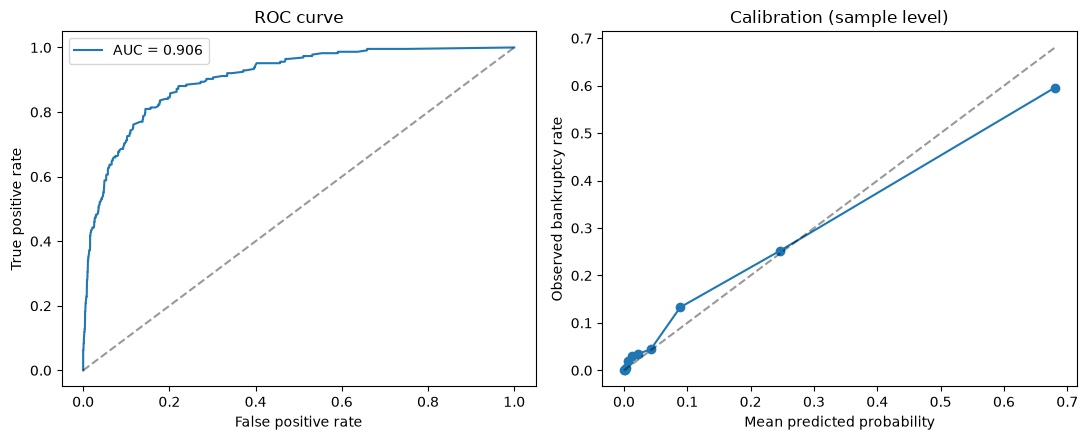

In [10]:
w_pop = population_weights(y_test)

ap_pop   = average_precision_score(y_test, y_prob, sample_weight=w_pop)
prec_pop = precision_score(y_test, y_pred, sample_weight=w_pop)
f1_pop   = 2 * prec_pop * rec_t / (prec_pop + rec_t)

print(f"Mean probability:  sample {y_prob.mean():.4f} (actual {y_test.mean():.4f})   "
      f"population {np.average(to_population_prob(y_prob), weights=w_pop):.4f} "
      f"(actual {np.average(y_test, weights=w_pop):.4f})")

# ── Metrics table: sample vs population ──────────────────────
test_metrics = pd.DataFrame({
    "metric": ["Bankruptcy rate", "ROC-AUC", "Average Precision",
               "Precision at threshold", "Recall at threshold", "F1 at threshold",
               "Threshold (probability)"],
    "sample":     [y_test.mean(), roc_auc, ap, prec_t, rec_t, f1_t, THRESHOLD],
    "population": [np.average(y_test, weights=w_pop), roc_auc, ap_pop,
                   prec_pop, rec_t, f1_pop, float(to_population_prob(THRESHOLD))],
}).round(4)
save_result(test_metrics, "test_metrics.csv")
print(test_metrics.to_string(index=False))

# ── Precision-recall curves at both base rates ────────────────
pr_parts = []
for level, weights in [("sample", None), ("population", w_pop)]:
    p, r, _ = precision_recall_curve(y_test, y_prob, sample_weight=weights)
    r, p = thin(r, p)
    pr_parts.append(pd.DataFrame({"level": level, "recall": r, "precision": p}))
save_result(pd.concat(pr_parts).round(4), "pr_curve.csv")

# ── Calibration: 10 equal-sized groups by predicted probability ─
calib = (
    pd.DataFrame({"pred": y_prob, "actual": y_test,
                  "bin": pd.qcut(y_prob, 10, labels=False, duplicates="drop")})
    .groupby("bin")
    .agg(mean_predicted=("pred", "mean"), observed_rate=("actual", "mean"),
         companies=("actual", "size"))
    .reset_index().round(4)
)
save_result(calib, "calibration.csv")

# ── Quick visual check (not saved — the app draws its own) ───
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(roc_points["fpr"], roc_points["tpr"], label=f"AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
axes[0].legend()
axes[1].plot(calib["mean_predicted"], calib["observed_rate"], "o-")
lim = max(calib["mean_predicted"].max(), calib["observed_rate"].max())
axes[1].plot([0, lim], [0, lim], "k--", alpha=0.4)
axes[1].set(xlabel="Mean predicted probability", ylabel="Observed bankruptcy rate",
            title="Calibration (sample level)")
plt.tight_layout()
plt.show()

## 11. What drives the predictions (SHAP)

SHAP splits each prediction into a contribution from every feature, on the model's log-odds scale. The population correction does not change these contributions: on the log-odds scale it adds the same constant to every prediction, shifting only the baseline.

Only aggregates are saved:

- **Importance:** mean absolute SHAP value per feature.
- **Typical profile:** mean SHAP contribution per feature for bankrupt vs active companies, i.e. what pushes a typical bankrupt company's score up.
- **Dependence:** how a feature's contribution changes across its range, averaged within value bands of at least 20 companies (`MIN_GROUP`).

  saved results/shap_importance.csv
  saved results/shap_profile_by_class.csv
  saved results/shap_dependence.csv

Top 10 features (mean |SHAP|):
              feature  mean_abs_shap
        FE_debt_ratio         0.8332
       P/L before tax         0.3591
               FE_roa         0.3413
  Current liabilities         0.3343
 FE_equity_yoy_change         0.3064
 FE_debt_ratio_change         0.3029
        FE_roa_change         0.2344
 FE_assets_yoy_growth         0.2324
          Company Age         0.2235
FE_non_current_assets         0.2119


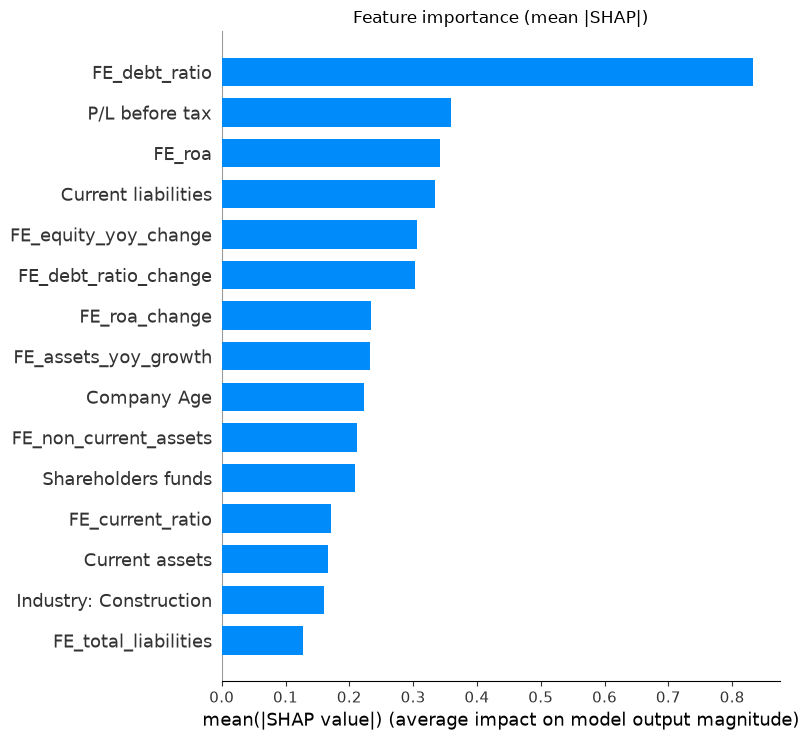

In [11]:
explainer   = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)
base_value  = float(np.atleast_1d(explainer.expected_value)[0])
shap_df     = pd.DataFrame(shap_values, columns=X_test.columns)

# ── Importance ────────────────────────────────────────────────
shap_importance = (
    shap_df.abs().mean()
    .sort_values(ascending=False)
    .rename("mean_abs_shap").rename_axis("feature").reset_index().round(4)
)

# ── Typical profile by class ──────────────────────────────────
shap_profile = (
    shap_df.groupby(y_test).mean().T
    .rename(columns={0: "mean_shap_active", 1: "mean_shap_bankrupt"})
    .rename_axis("feature").reset_index()
)
shap_profile["base_value"] = base_value
shap_profile = (shap_profile
                .set_index("feature").loc[shap_importance["feature"]]
                .reset_index().round(4))

# ── Binned dependence for the top numeric features ───────────
top_numeric = [f for f in shap_importance["feature"] if f in NUMERIC_FEATURES][:6]

dep_rows = []
for feat in top_numeric:
    x, s = X_test[feat], shap_df[feat]
    if x.dropna().nunique() <= 2:                       # binary flag
        groups = x.map({0.0: "0", 1.0: "1"})
    else:                                               # deciles
        groups = pd.qcut(x, 10, duplicates="drop").astype(str)
    groups = groups.where(x.notna(), "missing")
    for g, idx in groups.groupby(groups).groups.items():
        if len(idx) < MIN_GROUP:
            continue
        dep_rows.append({
            "feature": feat, "band": g,
            "feature_median": x.loc[idx].median(),
            "mean_shap": s.loc[idx].mean(),
            "companies": len(idx),
        })
shap_dependence = (pd.DataFrame(dep_rows)
                   .sort_values(["feature", "feature_median"], na_position="last")
                   .round(4))

save_result(shap_importance, "shap_importance.csv")
save_result(shap_profile,    "shap_profile_by_class.csv")
save_result(shap_dependence, "shap_dependence.csv")

print("\nTop 10 features (mean |SHAP|):")
print(shap_importance.head(10).to_string(index=False))

# Quick visual check (not saved)
shap.summary_plot(shap_values, X_test, plot_type="bar", max_display=15, show=False)
plt.title("Feature importance (mean |SHAP|)")
plt.tight_layout()
plt.show()

## 12. Demo model for the app's risk calculator

A compact model for the Streamlit app, where a user enters one year's figures and gets a risk estimate. It uses only what a user can type in: the five financial statement figures, company age and industry, plus the ratios computed from them. It needs no year-over-year history.

The app must compute the ratios exactly as in `01_Build_dataset`. The rules are saved alongside the model. Its own test performance is reported, so the app can state honestly how accurate the estimate is.

> Before publishing the app, confirm with TAMK that sharing a model trained on the licensed data is permitted.

In [12]:
DEMO_FEATURES = [
    "Company Age",
    "Total assets", "Current assets", "Current liabilities",
    "Shareholders funds", "P/L before tax",
    "FE_total_liabilities", "FE_non_current_assets",
    "FE_debt_ratio", "FE_current_ratio", "FE_roa",
    "FE_negative_equity", "FE_negative_pl",
]

Xd_train = make_features(df_train, DEMO_FEATURES)
Xd_test  = make_features(df_test,  DEMO_FEATURES)

demo_model = xgb.XGBClassifier(**XGB_PARAMS)
demo_model.fit(Xd_train, y_train)

pd_test = demo_model.predict_proba(Xd_test)[:, 1]
demo_auc = roc_auc_score(y_test, pd_test)
demo_ap  = average_precision_score(y_test, pd_test)
print(f"Demo model test ROC-AUC {demo_auc:.4f}   AP {demo_ap:.4f}   "
      f"(full model: {roc_auc:.4f} / {ap:.4f})")

# Population-level score distribution of test companies, as deciles,
# so the app can show where an entered company sits ("riskier than
# X% of companies") without storing any company-level data.
pop_scores = to_population_prob(pd_test)
deciles = np.quantile(pop_scores, np.linspace(0, 1, 11))

demo_model.save_model(os.path.join(RESULTS_DIR, "demo_model.json"))
demo_meta = {
    "features": list(Xd_train.columns),
    "industries": list(ohe.categories_[0]),
    "odds_factor": ODDS_FACTOR,
    "population_rate": UNIVERSE_RATE,
    "test_roc_auc": round(demo_auc, 4),
    "test_avg_precision": round(demo_ap, 4),
    "population_score_deciles": [round(float(d), 6) for d in deciles],
    "feature_rules": {
        "FE_total_liabilities":  "Total assets - Shareholders funds",
        "FE_non_current_assets": "Total assets - Current assets",
        "FE_debt_ratio":         "FE_total_liabilities / Total assets",
        "FE_current_ratio":      "Current assets / Current liabilities",
        "FE_roa":                "P/L before tax / Total assets",
        "FE_negative_equity":    "1 if Shareholders funds < 0 else 0",
        "FE_negative_pl":        "1 if P/L before tax < 0 else 0",
        "division_rule":         "ratio is missing (NaN) if |denominator| < 1000 EUR",
        "probability":           "apply odds_factor to the model output to get the population probability",
    },
}
with open(os.path.join(RESULTS_DIR, "demo_model_meta.json"), "w", encoding="utf-8") as f:
    json.dump(demo_meta, f, indent=2, ensure_ascii=False)
print("  saved results/demo_model.json")
print("  saved results/demo_model_meta.json")

Demo model test ROC-AUC 0.8931   AP 0.5384   (full model: 0.9059 / 0.6230)
  saved results/demo_model.json
  saved results/demo_model_meta.json


## 13. Results summary

In [13]:
summary = pd.DataFrame([
    ("Companies in model data",          len(df)),
    ("Bankrupt companies",               n_bankrupt),
    ("Bankruptcy rate (sample)",         round(SAMPLE_RATE, 4)),
    ("Bankruptcy rate (population)",     round(UNIVERSE_RATE, 4)),
    ("CV ROC-AUC (validation, mean)",    round(cv_folds["val_roc_auc"].mean(), 4)),
    ("CV ROC-AUC (validation, std)",     round(cv_folds["val_roc_auc"].std(), 4)),
    ("CV Avg Precision (validation)",    round(cv_folds["val_avg_precision"].mean(), 4)),
    ("Test ROC-AUC",                     round(roc_auc, 4)),
    ("Test Avg Precision (sample)",      round(ap, 4)),
    ("Test Avg Precision (population)",  round(ap_pop, 4)),
    ("Test precision (sample)",          round(prec_t, 4)),
    ("Test precision (population)",      round(prec_pop, 4)),
    ("Test recall",                      round(rec_t, 4)),
    ("Threshold (sample probability)",   round(THRESHOLD, 4)),
    ("Top feature 1",                    shap_importance["feature"].iloc[0]),
    ("Top feature 2",                    shap_importance["feature"].iloc[1]),
    ("Top feature 3",                    shap_importance["feature"].iloc[2]),
    ("Demo model test ROC-AUC",          round(demo_auc, 4)),
], columns=["item", "value"])

save_result(summary, "results_summary.csv")
print(summary.to_string(index=False))

  saved results/results_summary.csv
                           item          value
        Companies in model data          10123
             Bankrupt companies           1129
       Bankruptcy rate (sample)         0.1115
   Bankruptcy rate (population)         0.0177
  CV ROC-AUC (validation, mean)         0.9024
   CV ROC-AUC (validation, std)         0.0185
  CV Avg Precision (validation)         0.6249
                   Test ROC-AUC         0.9059
    Test Avg Precision (sample)          0.623
Test Avg Precision (population)         0.2755
        Test precision (sample)         0.4984
    Test precision (population)          0.125
                    Test recall         0.6814
 Threshold (sample probability)         0.2355
                  Top feature 1  FE_debt_ratio
                  Top feature 2 P/L before tax
                  Top feature 3         FE_roa
        Demo model test ROC-AUC         0.8931
